# Практична робота №4
## Мініпроєкт «Порівняння класичних моделей класифікації»
**Частина І:** Підготовка даних, Pipeline і логістична регресія  
**Дисципліна:** Розпізнавання образів і класичне машинне навчання  
**Студентка:** Софія Фесенко  
**Група:** ІН-32  

### Постановка задачі:
- **Об'єкт дослідження:** медичні показники та клінічні характеристики пацієнтів.
- **Цільова змінна:** `target` (наявність або відсутність ознак серцевого захворювання).
- **Кількість класів:** 2 (бінарна класифікація: 0 - відсутність захворювання, 1 — наявність ознак захворювання).
- **Позитивний клас:** `1`.
- **Основна метрика:** F1-міра (`F1-macro` / `F1`) для збалансованої оцінки точності й повноти.

In [11]:
from pathlib import Path
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
from IPython.display import display

print("Бібліотеки успішно імпортовано.")

Бібліотеки успішно імпортовано.


In [12]:
from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/pattern-recognition-practice/classification-mini-project")
DATA_PATH = PROJECT_DIR / "data" / "heart_disease.csv"
MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Шлях до даних:", DATA_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Шлях до даних: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/data/heart_disease.csv


## 1. Завантаження та первинна перевірка даних
На цьому етапі ми завантажуємо набір даних `heart_disease.csv`, перевіряємо його розмір, типи стовпців, наявність пропусків та розподіл цільової змінної. Згідно з вимогами мініпроєкту, значення цільової змінної (які в оригіналі містили рівні від 0 до 4) переведено у бінарний формат: `0` - відсутність захворювання, `1` - наявність ознак захворювання.

In [13]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Файл не знайдено за шляхом: {DATA_PATH}")

column_names = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
    'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'
]

data = pd.read_csv(DATA_PATH, header=None, names=column_names, na_values="?")

display(data.head())
print("Розмір таблиці:", data.shape)
print("\nТипи даних:")
print(data.dtypes)
print("\nКількість пропусків у колонках:")
print(data.isna().sum())

# Перетворення цільової змінної у бінарний формат (0 - немає, 1 - є)
#  значення від 1 до 4 об'єднуються в клас 1
data["target"] = data["target"].apply(lambda x: 1 if x > 0 else 0)

print("\nРозподіл класів у цільовій змінній (target):")
print(data["target"].value_counts(normalize=True).mul(100).round(2))

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Розмір таблиці: (303, 14)

Типи даних:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

Кількість пропусків у колонках:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Розподіл класів у цільовій змінній (target):
target
0    54.13
1    45.87
Name: proportion, dtype: float64


## 2. Формування вибірок (Train/Test Split)
Відповідно до єдиних правил експерименту, початковий набір даних розділяється на навчальну (80%) та тестову (20%) вибірки один раз за допомогою `train_test_split` із параметрами `stratify=y` та `random_state=42`. Тестова вибірка залишається закритою для будь-яких експериментів, підбору параметрів чи порівняння моделей.

In [14]:
X = data.drop(columns=["target"])
y = data["target"]

# Фіксований розрив 80/20 зі стратифікацією
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Розподіл класів у y_train (%):\n", y_train.value_counts(normalize=True).mul(100).round(2))
print("Розподіл класів у y_test (%):\n", y_test.value_counts(normalize=True).mul(100).round(2))

X_train: (242, 13)
X_test: (61, 13)
Розподіл класів у y_train (%):
 target
0    54.13
1    45.87
Name: proportion, dtype: float64
Розподіл класів у y_test (%):
 target
0    54.1
1    45.9
Name: proportion, dtype: float64


## 3. Налаштування схеми крос-валідації
Для всіх подальших експериментів та порівняння моделей використовується єдина 5-кратна стратифікована крос-валідація (`StratifiedKFold`). Це гарантує, що всі алгоритми оцінюватимуться на однакових фолдах, забезпечуючи чесність порівняння.

In [15]:
# Єдина схема крос-валідації для всіх моделей мініпроєкту
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Схема StratifiedKFold успішно створена (n_splits=5).")

Схема StratifiedKFold успішно створена (n_splits=5).


## 4. Побудова конвеєра (Pipeline) попередньої обробки
Щоб уникнути витоку даних (*data leakage*), усі операції з заповнення пропусків, масштабування та кодування об'єднуються в єдиний `ColumnTransformer` і `Pipeline`. Усі правила обчислюються виключно на навчальних фолдах крос-валідації.
- **Числові ознаки:** медіанна імпутація + стандартизація (`StandardScaler`).
- **Категоріальні ознаки:** модальна імпутація + One-Hot кодування.

In [16]:
# Визначення числових та категоріальних ознак
numeric_columns = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
categorical_columns = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

# Конвеєр для числових ознак (медіанна імпутація + стандартизація)
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Конвеєр для категоріальних ознак (імпутація модою + One-Hot кодування)
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Об'єднання в ColumnTransformer
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

# 1. Pipeline зі стандартизацією
lr_scaled_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

# 2. Pipeline без стандартизації
numeric_unscaled_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", "passthrough")
])

preprocessor_unscaled = ColumnTransformer([
    ("num", numeric_unscaled_pipeline, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

lr_unscaled_pipeline = Pipeline([
    ("preprocessor", preprocessor_unscaled),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

print("Конвеєри успішно налаштовано.")

Конвеєри успішно налаштовано.


## 5. Дослідження впливу масштабування на Логістичну регресію
Порівняємо два варіанти конвеєра: без стандартизації числових ознак та зі стандартизацією (`StandardScaler`), використовуючи крос-валідацію за метрикою `F1-macro` та `ROC AUC`.

In [17]:
def evaluate_cv(pipeline, X_tr, y_tr, cv):
    f1_scores = cross_val_score(pipeline, X_tr, y_tr, cv=cv, scoring="f1_macro")
    roc_auc_scores = cross_val_score(pipeline, X_tr, y_tr, cv=cv, scoring="roc_auc")
    return {
        "CV F1 (mean)": f1_scores.mean(),
        "CV F1 (std)": f1_scores.std(),
        "CV ROC AUC (mean)": roc_auc_scores.mean()
    }

res_unscaled = evaluate_cv(lr_unscaled_pipeline, X_train, y_train, cv_strategy)
res_scaled = evaluate_cv(lr_scaled_pipeline, X_train, y_train, cv_strategy)

scaling_comparison = pd.DataFrame([
    {"Model": "Logistic Regression (Without Scaler)", **res_unscaled},
    {"Model": "Logistic Regression (With StandardScaler)", **res_scaled}
])

display(scaling_comparison.round(4))

,Model,CV F1 (mean),CV F1 (std),CV ROC AUC (mean)
0,Logistic Regression (Without Scaler),0.8441,0.0083,0.8997
1,Logistic Regression (With StandardScaler),0.8441,0.0083,0.9025


## 6. Дослідження L1- та L2-регуляризації
Дослідимо вплив параметру сили регуляризації $C$ для логістичної регресії. Малі значення $C$ означають сильну регуляризацію, великі - слабку. Для L1-регуляризації використаємо розв'язувач `saga`, який підтримує цей тип штрафу.

In [18]:
from sklearn.model_selection import GridSearchCV

# Створюємо параметричну сітку для перевірки C та типів штрафу (penalty)
param_grid = [
    {
        'classifier__penalty': ['l2'],
        'classifier__C': [0.01, 0.1, 1, 10, 100],
        'classifier__solver': ['lbfgs']
    },
    {
        'classifier__penalty': ['l1'],
        'classifier__C': [0.01, 0.1, 1, 10, 100],
        'classifier__solver': ['saga']
    }
]

# Використання GridSearchCV з єдиною схемою крос-валідації та метрикою f1_macro
grid_search = GridSearchCV(
    estimator=lr_scaled_pipeline,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv_strategy,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Найкращі параметри за CV:", grid_search.best_params_)
print("Найкращий CV F1-macro:", round(grid_search.best_score_, 4))

# Зберігаємо результати перебору в DataFrame для аналізу та побудови графіка
cv_results = pd.DataFrame(grid_search.cv_results_)
display(cv_results[['param_classifier__C', 'param_classifier__penalty', 'mean_test_score', 'std_test_score']].sort_values(by='mean_test_score', ascending=False).head(10))

Найкращі параметри за CV: {'classifier__C': 10, 'classifier__penalty': 'l2', 'classifier__solver': 'lbfgs'}
Найкращий CV F1-macro: 0.8531


,param_classifier__C,param_classifier__penalty,mean_test_score,std_test_score
4,100.00,l2,0.853112,0.017145
3,10.00,l2,0.853112,0.017145
9,100.00,l1,0.853112,0.017145
8,10.00,l1,0.849026,0.014527
2,1.00,l2,0.844128,0.008331
1,0.10,l2,0.835244,0.025116
7,1.00,l1,0.831550,0.013035
6,0.10,l1,0.814487,0.024424
0,0.01,l2,0.799398,0.016010
5,0.01,l1,0.351197,0.002725


## 7. Візуалізація залежності CV F1 від параметра C
Будуємо графік залежності якості моделі (CV F1-macro) від значення параметра $C$ окремо для L1 та L2 регуляризації.

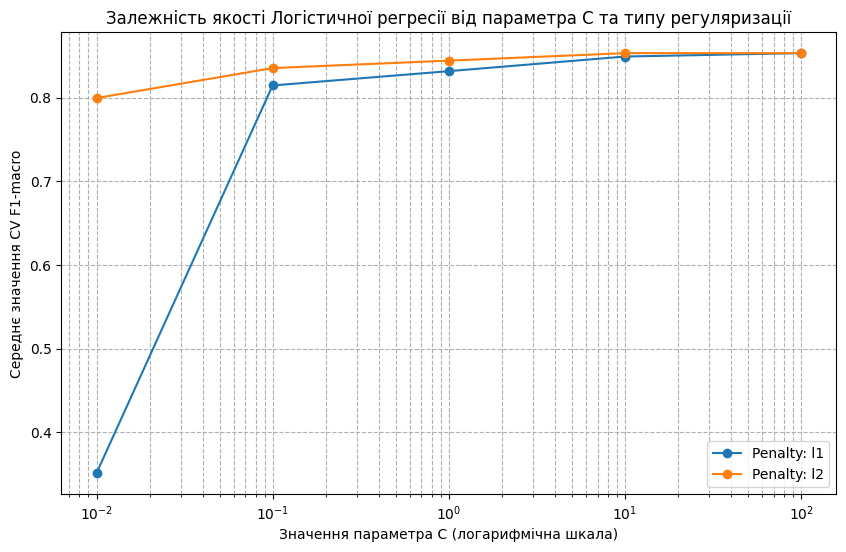

In [19]:
plt.figure(figsize=(10, 6))

for penalty in ['l1', 'l2']:
    subset = cv_results[cv_results['param_classifier__penalty'] == penalty]
    plt.plot(
        subset['param_classifier__C'].astype(float),
        subset['mean_test_score'],
        marker='o',
        label=f"Penalty: {penalty}"
    )

plt.xscale('log')
plt.xlabel("Значення параметра C (логарифмічна шкала)")
plt.ylabel("Середнє значення CV F1-macro")
plt.title("Залежність якості Логістичної регресії від параметра C та типу регуляризації")
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

## 8. Аналіз коефіцієнтів найкращої моделі
Отримаємо назви ознак після препроцесингу та визначимо п'ять ознак із найбільшими за модулем коефіцієнтами для найкращої логістичної регресії.

In [20]:
# Отримуємо найкращий естиматор з GridSearchCV
best_lr_model = grid_search.best_estimator_

# Отримуємо назви ознак після трансформації
preprocessor_fitted = best_lr_model.named_steps['preprocessor']
num_feature_names = numeric_columns
cat_encoder = preprocessor_fitted.named_transformers_['cat'].named_steps['encoder']
cat_feature_names = list(cat_encoder.get_feature_names_out(categorical_columns))

all_feature_names = num_feature_names + cat_feature_names

# Отримуємо коефіцієнти моделі
coefficients = best_lr_model.named_steps['classifier'].coef_[0]

# DataFrame для зручного аналізу
coef_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Coefficient': coefficients,
    'Abs_Coefficient': np.abs(coefficients)
})

# Сортуємо за модулем коефіцієнта
top_coefs = coef_df.sort_values(by='Abs_Coefficient', ascending=False).head(5)

print("ТОП-5 ознак за найбільшими за модулем коефіцієнтами:")
display(top_coefs)

ТОП-5 ознак за найбільшими за модулем коефіцієнтами:


,Feature,Coefficient,Abs_Coefficient
21,ca_0.0,-1.928486,1.928486
10,cp_4.0,1.194655,1.194655
27,thal_7.0,0.982694,0.982694
7,cp_1.0,-0.888944,0.888944
5,sex_0.0,-0.868073,0.868073


# Практична робота №5
## k-NN та ймовірнісні методи класифікації
У цій практичній роботі ми дослідимо метод k-найближчих сусідів ($k$-NN) із різними масштабами, значеннями $k$ та мірами відстаней, а також побудуємо ймовірнісні класифікатори: Gaussian Naive Bayes, Linear Discriminant Analysis (LDA) та Quadratic Discriminant Analysis (QDA).

## 1. Дослідження методу k-NN (k-найближчих сусідів)
Дослідимо, як впливає стандартизація ознак, вибір кількості сусідів ($k \in \{3, 5, 7, 9, 11, 15\}$) та міра відстані (евклідова чи манхеттенська) на якість моделі за крос-валідацією.

In [21]:
from sklearn.neighbors import KNeighborsClassifier

# 1. Порівняння k-NN без масштабування та зі StandardScaler (при k=5 за замовчуванням)
knn_unscaled_pipeline = Pipeline([
    ("preprocessor", preprocessor_unscaled),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

knn_scaled_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

res_knn_unscaled = evaluate_cv(knn_unscaled_pipeline, X_train, y_train, cv_strategy)
res_knn_scaled = evaluate_cv(knn_scaled_pipeline, X_train, y_train, cv_strategy)

knn_scaling_df = pd.DataFrame([
    {"Model": "k-NN (Without Scaler)", **res_knn_unscaled},
    {"Model": "k-NN (With StandardScaler)", **res_knn_scaled}
])

print("Порівняння впливу масштабування на k-NN:")
display(knn_scaling_df.round(4))

Порівняння впливу масштабування на k-NN:


,Model,CV F1 (mean),CV F1 (std),CV ROC AUC (mean)
0,k-NN (Without Scaler),0.5668,0.0206,0.6419
1,k-NN (With StandardScaler),0.8192,0.0305,0.8712


## 2. Підбір кількості сусідів (k) та міри відстані для k-NN
Перевіримо значення параметра $k \in \{3, 5, 7, 9, 11, 15\}$ для масштабованого $k$-NN, побудуємо графік залежності CV F1 від $k$, а для найкращого $k$ порівняємо евклідову та манхеттенську відстані.

,k,CV F1 (mean),CV F1 (std),CV ROC AUC (mean)
0,3,0.8197,0.0208,0.8709
1,5,0.8192,0.0305,0.8712
2,7,0.8154,0.0160,0.8721
3,9,0.8104,0.0210,0.8744
4,11,0.8055,0.0177,0.8806
5,15,0.7933,0.0200,0.8729


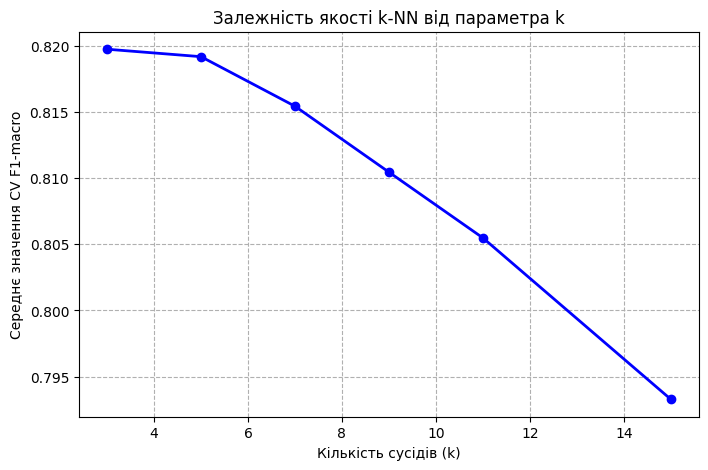

In [22]:
k_values = [3, 5, 7, 9, 11, 15]
knn_cv_results = []

for k in k_values:
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])
    res = evaluate_cv(pipe, X_train, y_train, cv_strategy)
    knn_cv_results.append({
        "k": k,
        **res
    })

knn_k_df = pd.DataFrame(knn_cv_results)
display(knn_k_df.round(4))

# Графік k -> CV F1
plt.figure(figsize=(8, 5))
plt.plot(knn_k_df['k'], knn_k_df['CV F1 (mean)'], marker='o', color='b', linestyle='-', linewidth=2)
plt.xlabel("Кількість сусідів (k)")
plt.ylabel("Середнє значення CV F1-macro")
plt.title("Залежність якості k-NN від параметра k")
plt.grid(True, linestyle="--")
plt.show()

In [23]:
# Знаходимо найкраще k за максимальним CV F1
best_k = int(knn_k_df.loc[knn_k_df['CV F1 (mean)'].idxmax()]['k'])
print(f"Найкраще значення k за крос-валідацією: {best_k}")

# Порівняння мір відстаней (p=2 - евклідова, p=1 - манхеттенська) for best_k
distance_results = []
for p_val, dist_name in [(2, "Евклідова (L2)"), (1, "Манхеттенська (L1)")]:
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=best_k, p=p_val))
    ])
    res = evaluate_cv(pipe, X_train, y_train, cv_strategy)
    distance_results.append({
        "Міра відстані": dist_name,
        **res
    })

distance_df = pd.DataFrame(distance_results)
print(f"\nПорівняння мір відстаней для k = {best_k}:")
display(distance_df.round(4))

Найкраще значення k за крос-валідацією: 3

Порівняння мір відстаней для k = 3:


,Міра відстані,CV F1 (mean),CV F1 (std),CV ROC AUC (mean)
0,Евклідова (L2),0.8197,0.0208,0.8709
1,Манхеттенська (L1),0.8358,0.0255,0.8768


## 3. Ймовірнісні класифікатори (GaussianNB, LDA, QDA)
Побудуємо та оцінимо за крос-валідацією три класичні ймовірнісні моделі. Для цього використаємо окремі конвеєри, які включають наш препроцесор .

In [24]:
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis

# Створюємо пайплайни для ймовірнісних моделей
gnb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GaussianNB())
])

lda_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LinearDiscriminantAnalysis())
])

# Для QDA додаємо невеликий reg_param на випадок нестабільності коваріаційних матриць
qda_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", QuadraticDiscriminantAnalysis(reg_param=0.01))
])

# Оцінюємо за крос-валідацією
res_gnb = evaluate_cv(gnb_pipeline, X_train, y_train, cv_strategy)
res_lda = evaluate_cv(lda_pipeline, X_train, y_train, cv_strategy)
res_qda = evaluate_cv(qda_pipeline, X_train, y_train, cv_strategy)

prob_models_df = pd.DataFrame([
    {"Model": "Gaussian Naive Bayes", **res_gnb},
    {"Model": "Linear Discriminant Analysis (LDA)", **res_lda},
    {"Model": "Quadratic Discriminant Analysis (QDA)", **res_qda}
])

print("Порівняння ймовірнісних моделей:")
display(prob_models_df.round(4))

Порівняння ймовірнісних моделей:


,Model,CV F1 (mean),CV F1 (std),CV ROC AUC (mean)
0,Gaussian Naive Bayes,0.7377,0.0258,0.8773
1,Linear Discriminant Analysis (LDA),0.8352,0.0217,0.8993
2,Quadratic Discriminant Analysis (QDA),0.7872,0.0408,0.8343


## 4. Метод опорних векторів (SVM) та пошук гіперпараметрів
Побудуємо лінійну SVM та SVM з RBF-ядром на масштабованих даних. За допомогою GridSearchCV знайдемо найкращі параметри $C$ та $\gamma$ за крос-валідацією.

In [25]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

# Базовий конвеєр для SVM із масштабуванням
svm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(random_state=42))
])

# Сітка параметрів для лінійного та RBF ядер згідно з вимогами
param_grid_svm = [
    {
        'classifier__kernel': ['linear'],
        'classifier__C': [0.1, 1, 10]
    },
    {
        'classifier__kernel': ['rbf'],
        'classifier__C': [0.1, 1, 10],
        'classifier__gamma': ['scale', 0.01, 0.1]
    }
]

grid_svm = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid_svm,
    scoring='f1_macro',
    cv=cv_strategy,
    n_jobs=-1
)

grid_svm.fit(X_train, y_train)

print("Найкращі параметри SVM:", grid_svm.best_params_)
print("Найкращий CV F1-macro для SVM:", round(grid_svm.best_score_, 4))

# Виводимо топ конфігурацій
svm_results_df = pd.DataFrame(grid_svm.cv_results_)
display(svm_results_df[['param_classifier__kernel', 'param_classifier__C', 'param_classifier__gamma', 'mean_test_score', 'std_test_score']].sort_values(by='mean_test_score', ascending=False).head(5))

Найкращі параметри SVM: {'classifier__C': 10, 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf'}
Найкращий CV F1-macro для SVM: 0.8477


,param_classifier__kernel,param_classifier__C,param_classifier__gamma,mean_test_score,std_test_score
10,rbf,10.0,0.01,0.847707,0.025795
0,linear,0.1,NaN,0.824740,0.039133
1,linear,1.0,NaN,0.823548,0.021938
2,linear,10.0,NaN,0.819825,0.024436
7,rbf,1.0,0.01,0.818645,0.022709


# Практична робота №7
## Порівняння моделей, фінальне тестування і збереження Pipeline
Збережемо результати всіх наших кандидатів у єдину таблицю, побудуємо крос-валідаційні ROC-криві за позавибірковими прогнозами, оберемо фінальну модель до відкриття тесту та один раз перевіримо її на `X_test`.

In [26]:
# Збираємо найкращі моделі з попередніх кроків у словник кандидатів
candidates = {
    "Logistic Regression": grid_search.best_estimator_,
    "k-NN": Pipeline([("preprocessor", preprocessor), ("classifier", KNeighborsClassifier(n_neighbors=3, p=1))]),
    "GaussianNB": gnb_pipeline,
    "LDA": lda_pipeline,
    "QDA": qda_pipeline,
    "SVM (RBF)": grid_svm.best_estimator_
}

comparison_data = []

for name, model in candidates.items():
    f1 = cross_val_score(model, X_train, y_train, cv=cv_strategy, scoring="f1_macro")
    recall = cross_val_score(model, X_train, y_train, cv=cv_strategy, scoring="recall")
    roc_auc = cross_val_score(model, X_train, y_train, cv=cv_strategy, scoring="roc_auc")

    comparison_data.append({
        "Model": name,
        "CV F1 (mean)": f1.mean(),
        "CV F1 (std)": f1.std(),
        "CV Recall (mean)": recall.mean(),
        "CV ROC AUC (mean)": roc_auc.mean()
    })

cv_comparison_df = pd.DataFrame(comparison_data).sort_values(by="CV F1 (mean)", ascending=False)

print("Єдина таблиця порівняння кандидатів за крос-валідацією:")
display(cv_comparison_df.round(4))

# Зберігаємо таблицю у папку reports
cv_comparison_df.to_csv(REPORTS_DIR / "cv_model_comparison.csv", index=False)

Єдина таблиця порівняння кандидатів за крос-валідацією:


,Model,CV F1 (mean),CV F1 (std),CV Recall (mean),CV ROC AUC (mean)
0,Logistic Regression,0.8531,0.0171,0.8016,0.8995
5,SVM (RBF),0.8477,0.0258,0.7830,0.8968
1,k-NN,0.8358,0.0255,0.7917,0.8768
3,LDA,0.8352,0.0217,0.7656,0.8993
4,QDA,0.7872,0.0408,0.7743,0.8343
2,GaussianNB,0.7377,0.0258,0.8458,0.8773


## Побудова крос-валідаційних ROC-кривих
Отримаємо позавибіркові прогнози (`cross_val_predict`) для кожного кандидата та побудуємо спільний графік ROC-кривих на навчальній вибірці.

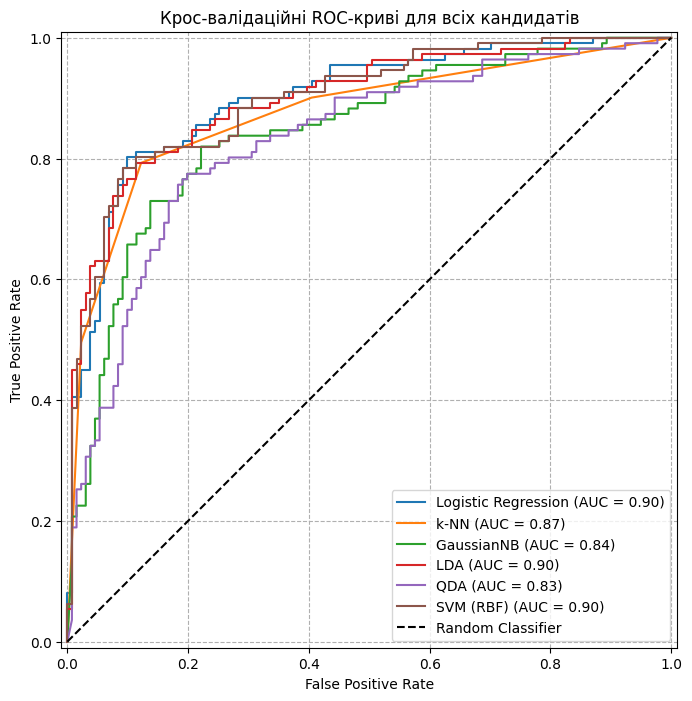

In [27]:
plt.figure(figsize=(10, 8))

for name, model in candidates.items():
    # Отримуємо позавибіркові ймовірності або значення decision_function
    if hasattr(model, "predict_proba"):
        y_oof_score = cross_val_predict(model, X_train, y_train, cv=cv_strategy, method="predict_proba")[:, 1]
    else:
        y_oof_score = cross_val_predict(model, X_train, y_train, cv=cv_strategy, method="decision_function")

    RocCurveDisplay.from_predictions(
        y_train, y_oof_score, name=name, ax=plt.gca()
    )

plt.plot([0, 1], [0, 1], 'k--', label="Random Classifier")
plt.title("Крос-валідаційні ROC-криві для всіх кандидатів")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--")
plt.show()

## Фінальне оцінювання на тестовій вибірці та збереження моделі
Зафіксувавши Логістичну регресію як найкращу модель за крос-валідацією, навчимо її на всій навчальній вибірці та виконаємо **одноразову** перевірку на закритій тестовій вибірці `X_test`. Також збережемо фінальний Pipeline на диск.

In [28]:
# Вибираємо фінальну модель
final_pipeline = candidates["Logistic Regression"]

# Навчаємо на всій навчальній вибірці
final_pipeline.fit(X_train, y_train)

# Робимо прогноз на тестовій вибірці
y_pred_test = final_pipeline.predict(X_test)
y_score_test = final_pipeline.predict_proba(X_test)[:, 1]

# Рахуємо тестові метрики
test_metrics = {
    "Model": "Logistic Regression (Final Test)",
    "Test Accuracy": accuracy_score(y_test, y_pred_test),
    "Test Precision": precision_score(y_test, y_pred_test),
    "Test Recall": recall_score(y_test, y_pred_test),
    "Test F1": f1_score(y_test, y_pred_test, average="macro"),
    "Test ROC AUC": roc_auc_score(y_test, y_score_test)
}

test_metrics_df = pd.DataFrame([test_metrics])
print("Фінальні метрики на тестовій вибірці:")
display(test_metrics_df.round(4))

# Зберігаємо тест-метрики у reports
test_metrics_df.to_csv(REPORTS_DIR / "final_test_metrics.csv", index=False)

# Зберігаємо весь фінальний Pipeline за допомогою joblib
MODEL_PATH = MODELS_DIR / "best_classifier.joblib"
joblib.dump(final_pipeline, MODEL_PATH)
print(f"\nФінальний Pipeline успішно збережено у файл: {MODEL_PATH}")

Фінальні метрики на тестовій вибірці:


,Model,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC AUC
0,Logistic Regression (Final Test),0.8689,0.8333,0.8929,0.8685,0.9632



Фінальний Pipeline успішно збережено у файл: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/models/best_classifier.joblib


Перевірка завантаженого Pipeline (прогнози для перших 3 об'єктів тесту): [0 1 0]


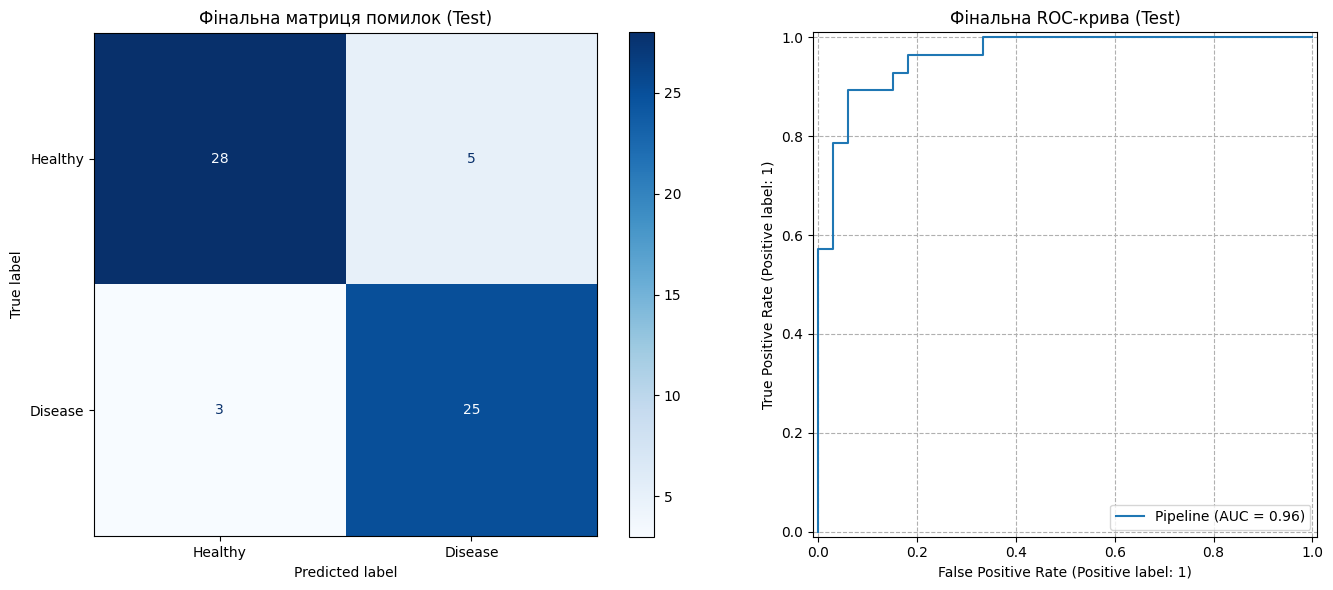

In [30]:
# Перевірка працездатності збереженого файлу
loaded_pipeline = joblib.load(MODEL_PATH)
test_preds_check = loaded_pipeline.predict(X_test.head(3))
print("Перевірка завантаженого Pipeline (прогнози для перших 3 об'єктів тесту):", test_preds_check)

# Побудова фінальної матриці помилок та ROC-кривої для тесту
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ConfusionMatrixDisplay.from_estimator(loaded_pipeline, X_test, y_test, ax=axes[0], cmap="Blues", display_labels=["Healthy", "Disease"])
axes[0].set_title("Фінальна матриця помилок (Test)")

RocCurveDisplay.from_estimator(loaded_pipeline, X_test, y_test, ax=axes[1])
axes[1].set_title("Фінальна ROC-крива (Test)")
axes[1].grid(True, linestyle="--")

plt.tight_layout()
plt.show()

In [31]:

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

cv_comparison_df.to_csv(REPORTS_DIR / "cv_model_comparison.csv", index=False)

print("Усі звіти та моделі успішно зафіксовані на Google Диску у папці classification-mini-project!")
print("Шлях до звітів:", REPORTS_DIR)
print("Шлях до моделі:", MODELS_DIR)

Усі звіти та моделі успішно зафіксовані на Google Диску у папці classification-mini-project!
Шлях до звітів: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/reports
Шлях до моделі: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/models
